# クラスタリング 4 手法を同じデータで比較

**出典**　機械学習 4 分野の教科書 — 第 9 章 3-A クラスタリング ／ 08 実装：4 手法を同じデータで比較する

**このノートのパス**　`ml-code/09_clustering/01_four_methods.ipynb`

**このノートで確かめること**
k-means / Ward / DBSCAN / GMM を**丸いかたまり**と**三日月形**の両方に当て、
**手法の前提とデータの形が合っているか**で結果が決まることを確かめる。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `scikit-learn numpy matplotlib` |
| 実行時間の目安 | 約 20 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q scikit-learn numpy matplotlib

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

RS = 42

# --- データ：丸いかたまり と 三日月形 の 2 種類を用意する ---
X_blob, _ = make_blobs(n_samples=400, centers=3, cluster_std=1.1, random_state=RS)
X_moon, _ = make_moons(n_samples=400, noise=0.06, random_state=RS)

# 距離を使う手法なので標準化は必須
X_blob = StandardScaler().fit_transform(X_blob)
X_moon = StandardScaler().fit_transform(X_moon)


def run_all(X, k=2):
    """4 手法を同じデータに当てて、ラベルを辞書で返す"""
    return {
        "k-means": KMeans(n_clusters=k, n_init=10,
                          random_state=RS).fit_predict(X),
        "Ward":    AgglomerativeClustering(n_clusters=k,
                                           linkage="ward").fit_predict(X),
        "DBSCAN":  DBSCAN(eps=0.30, min_samples=5).fit_predict(X),
        "GMM":     GaussianMixture(n_components=k, covariance_type="full",
                                   random_state=RS).fit_predict(X),
    }


def report(X, labels, name):
    n_cluster = len(set(labels) - {-1})        # -1 は DBSCAN のノイズ
    n_noise = int((labels == -1).sum())
    mask = labels != -1                        # シルエットはノイズを除いて計算する
    if len(set(labels[mask])) > 1:
        sil = f"{silhouette_score(X[mask], labels[mask]):.3f}"
    else:
        sil = "—"                              # クラスタが 1 つでは定義できない
    print(f"{name:8s} クラスタ数={n_cluster}  ノイズ={n_noise:3d}  silhouette={sil}")


print("=== 三日月形（非凸）===")
for name, labels in run_all(X_moon).items():
    report(X_moon, labels, name)

print("\n=== 丸いかたまり（凸・3 クラスタ）===")
for name, labels in run_all(X_blob, k=3).items():
    report(X_blob, labels, name)

=== 三日月形（非凸）===


  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


k-means  クラスタ数=2  ノイズ=  0  silhouette=0.494
Ward     クラスタ数=2  ノイズ=  0  silhouette=0.438
DBSCAN   クラスタ数=2  ノイズ=  1  silhouette=0.382
GMM      クラスタ数=2  ノイズ=  0  silhouette=0.494

=== 丸いかたまり（凸・3 クラスタ）===
k-means  クラスタ数=3  ノイズ=  0  silhouette=0.830
Ward     クラスタ数=3  ノイズ=  0  silhouette=0.830
DBSCAN   クラスタ数=3  ノイズ=  1  silhouette=0.831
GMM      クラスタ数=3  ノイズ=  0  silhouette=0.830


### 数字だけでは分からないので、必ず描いて見る

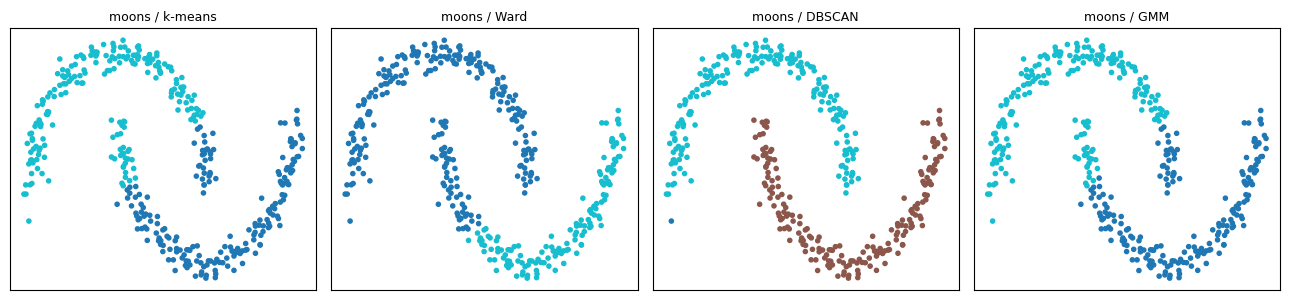

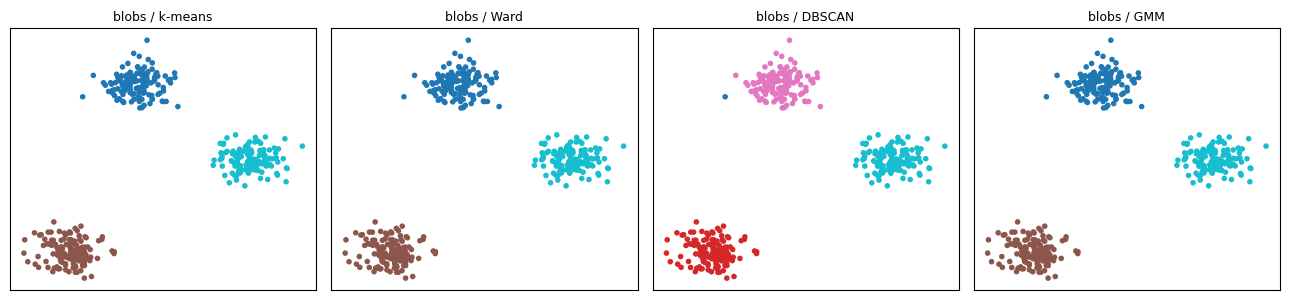

In [4]:
for X, k, title in [(X_moon, 2, "moons"), (X_blob, 3, "blobs")]:
    res = run_all(X, k=k)
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.1))
    for ax, (name, labels) in zip(axes, res.items()):
        ax.scatter(X[:, 0], X[:, 1], c=labels, s=9, cmap="tab10")
        ax.set_title(f"{title} / {name}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

## 読み取りどころ

- **三日月形では k-means・Ward・GMM が崩れ、DBSCAN だけが形どおりに割る。**前者 3 つは「クラスタは凸（丸い）」という前提を持っているため。
- **丸いかたまりでは逆に、DBSCAN の `eps` 調整が難しい。**この値はデータのスケールに強く依存するので、**標準化していないと機能しない**。
- ⚠️ **silhouette が高い＝正しい、ではない。**シルエットは「丸く固まっているか」を測る指標なので、**k-means に有利で DBSCAN に不利**という偏りがある。三日月形でそれが起きる。

**手法の前提とデータの形が合っているかを、まず絵で確認すること。**指標はそのあとの微調整に使う。